# Практика по лекции 4: baselines, метрики и схемы валидации

**Цель:** построить baselines, корректно сравнить их по нескольким метрикам, организовать backtesting и убедиться, что схема валидации не даёт утечек.

**Данные.** Ряд генерируется функцией `generate_time_series` из лабораторной работы: рост, две сезонности (1 час = 12 точек и 6 часов = 72 точки), шум. Выбросов и сдвигов здесь нет.

**Что адаптировано под наш ряд.** В лекции пример для дневных данных с недельной сезонностью и горизонтом 7:

| | Лекция | Наш ряд (шаг 5 минут) |
|---|---|---|
| сезонный период `s` | 7 | **72** точки (6 часов) |
| горизонт `H` | 7 | **72** точки (6 часов вперёд) |
| окно sliding `L` | 3–4 периода | **288** точек (4 периода) |
| шагов backtesting | 10 | 10 |

Seasonal Naive использует период 72: он включает и короткую сезонность (12 укладывается в 72 ровно 6 раз). Дополнительно для сравнения показан Seasonal Naive с неверным периодом 12.

**План:** 1) данные → 2) baselines → 3) backtesting (expanding и sliding) → 4) метрики → 5) сравнение и устойчивость → 6) интервалы → 7) утечка при случайном split → 8) выводы.

In [1]:
import os
import warnings
from datetime import datetime, timedelta
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.forecasting.theta import ThetaModel
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Данные

### Генератор из лабораторной работы (без изменений)

In [2]:
STEP_MINUTES = 5
PERIOD_1H = 12   # 1 час при шаге 5 минут
PERIOD_6H = 72   # 6 часов при шаге 5 минут

VARIANCE_MODES = ["const", "grow", "decay"]
TREND_MODES = ["none", "fast_up", "slow_up", "fast_down", "slow_down"]
SEASONALITY_MODES = ["none", "one", "two"]

# Суммарное изменение тренда за весь ряд
TREND_TOTAL = {"fast_up": 60.0, "slow_up": 15.0, "fast_down": -60.0, "slow_down": -15.0}


def _unique_path(path):
    if not os.path.exists(path):
        return path
    root, ext = os.path.splitext(path)
    i = 1
    while os.path.exists(f"{root}_{i}{ext}"):
        i += 1
    return f"{root}_{i}{ext}"


def generate_time_series(
    n_points=1000,
    variance="const",
    trend="none",
    seasonality="none",
    base=100.0,
    noise_std=2.0,
    seed=None,
    save_csv=True,
    csv_dir=".",
    save_plot=False,
    plot_path=None,
    show_plot=True,
):
    if n_points < 1:
        raise ValueError("n_points должно быть >= 1")

    rng = np.random.default_rng(seed)

    # Случайный выбор режимов
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    if variance not in VARIANCE_MODES:
        raise ValueError(f"Неизвестный режим дисперсии: {variance}")
    if trend not in TREND_MODES:
        raise ValueError(f"Неизвестный режим тренда: {trend}")
    if seasonality not in SEASONALITY_MODES:
        raise ValueError(f"Неизвестный режим сезонности: {seasonality}")

    # временная ось: с 00:00 текущего дня, шаг 5 минут
    start = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start + timedelta(minutes=STEP_MINUTES * i) for i in range(n_points)]

    idx = np.arange(n_points)
    progress = idx / max(n_points - 1, 1)

    # тренд
    trend_values = np.zeros(n_points) if trend == "none" else TREND_TOTAL[trend] * progress

    # сезонность
    season_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        season_values += 10.0 * np.sin(2 * np.pi * idx / PERIOD_1H)
    if seasonality == "two":
        season_values += 20.0 * np.sin(2 * np.pi * idx / PERIOD_6H)

    # дисперсия:
    if variance == "const":
        sigma = np.full(n_points, noise_std)
    elif variance == "grow":
        sigma = noise_std * (0.25 + 3.75 * progress)
    else:
        sigma = noise_std * (4.0 - 3.75 * progress)

    noise = rng.normal(0.0, 1.0, n_points) * sigma

    values = base + trend_values + season_values + noise
    params = {"n_points": n_points, "variance": variance, "trend": trend,
              "seasonality": seasonality, "seed": seed}

    if save_csv:
        name = "ts_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
        path = _unique_path(os.path.join(csv_dir, name))
        with open(path, "w", encoding="utf-8") as f:
            f.write("timestamp,value\n")
            for t, v in zip(timestamps, values):
                f.write(f"{t:%Y-%m-%d %H:%M:%S},{v:.6f}\n")
        params["csv_file"] = path

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(timestamps, values, lw=0.9)
    ax.set_title(f"variance={variance}, trend={trend}, seasonality={seasonality}, n={n_points}")
    ax.set_xlabel("Время")
    ax.set_ylabel("Значение")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()

    if save_plot:
        if plot_path is None:
            raise ValueError("Укажите plot_path для сохранения графика")
        os.makedirs(os.path.dirname(plot_path) or ".", exist_ok=True)
        fig.savefig(plot_path, dpi=150)
        params["plot_file"] = plot_path

    if show_plot:
        plt.show()
    else:
        plt.close(fig)

    return timestamps, values, params

{'n_points': 2880, 'variance': 'const', 'trend': 'fast_up', 'seasonality': 'two', 'seed': 21}
N = 2880 | S = 72 | H = 72 | L = 288 | первое тестовое окно с точки 2160


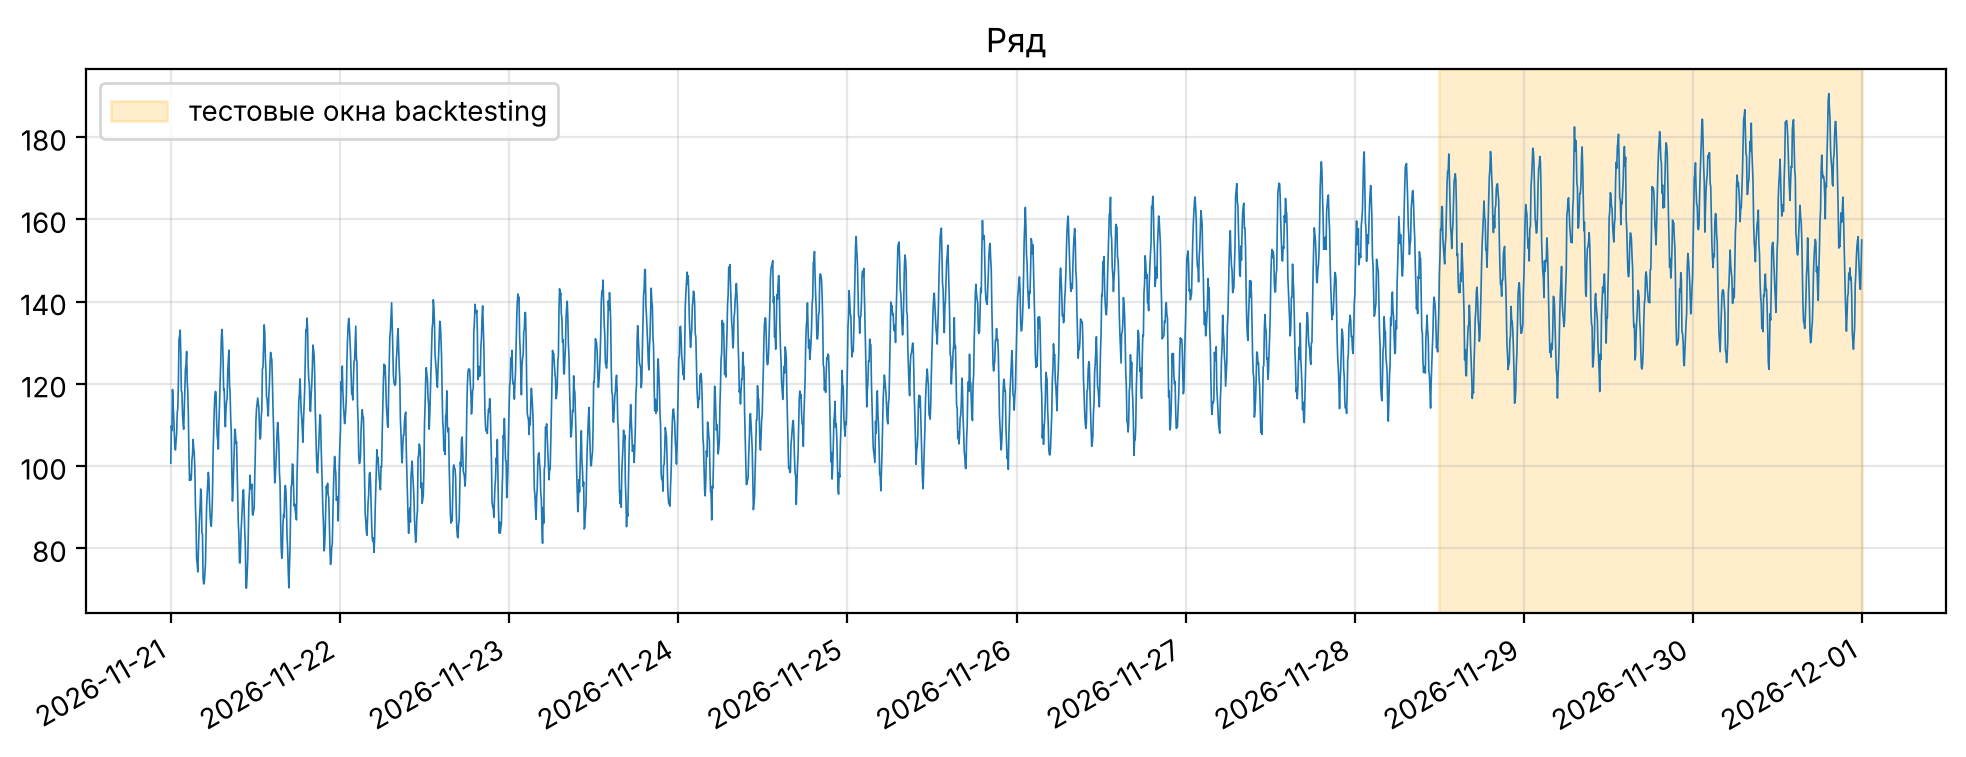

In [3]:
N = 2880
S = PERIOD_6H            # сезонный период: 72 точки
H = S                    # горизонт: 6 часов вперёд
N_STEPS = 10             # шагов backtesting
L = 4 * S                # окно для sliding: 4 периода
TEST_START = N - N_STEPS * H   # начало первого тестового окна

ts, vals, params = generate_time_series(
    n_points=N, variance="const", trend="fast_up", seasonality="two",
    seed=21, save_csv=False, show_plot=False,
)
print(params)
idx = pd.DatetimeIndex(ts, freq="5min")
y = pd.Series(np.asarray(vals), index=idx, name="y")
ya = y.to_numpy()
print("N =", N, "| S =", S, "| H =", H, "| L =", L, "| первое тестовое окно с точки", TEST_START)

fig, ax = plt.subplots()
ax.plot(y.index, y, lw=0.6)
ax.axvspan(y.index[TEST_START], y.index[-1], color="orange", alpha=0.2, label="тестовые окна backtesting")
ax.set_title("Ряд"); ax.legend(); fig.autofmt_xdate(); plt.show()

## 2. Baselines

* **Naive** — последнее значение; **Mean** — среднее по обучающей выборке; **Drift** — прямая от первого до последнего наблюдения;
* **Seasonal Naive** — значение на период `s` раньше;
* **Theta** — `ThetaModel` из statsmodels с аддитивной сезонной корректировкой (период 72). Сезонность ряда аддитивная, как показано в практике по лекции 2.

Все функции имеют одинаковый вид `f(train, H) → массив длины H`.

In [4]:
def naive(train, H):
    return np.repeat(train[-1], H)


def seasonal_naive(train, H, s=S):
    last_season = train[-s:]
    reps = int(np.ceil(H / s))
    return np.tile(last_season, reps)[:H]


def mean_fc(train, H):
    return np.repeat(train.mean(), H)


def drift(train, H):
    slope = (train[-1] - train[0]) / (len(train) - 1)
    return train[-1] + slope * np.arange(1, H + 1)


def theta(train, H):
    res = ThetaModel(train, period=S, deseasonalize=True, use_test=False, method="additive").fit()
    return np.asarray(res.forecast(H), dtype=float)


models = {
    "Naive": naive,
    "Seasonal Naive (s=72)": lambda tr, H: seasonal_naive(tr, H, s=S),
    "Mean": mean_fc,
    "Drift": drift,
    "Theta": theta,
    "Seasonal Naive (s=12), для сравнения": lambda tr, H: seasonal_naive(tr, H, s=12),
}

## 3. Backtesting: expanding и sliding window

На каждом шаге: обучение только на прошлом → прогноз на `H` точек → окно сдвигается на `H`. Тестовые окна у обеих схем **одинаковые** (чтобы сравнение было корректным), различается только обучающая выборка: у expanding она растёт, у sliding всегда равна `L = 288` точек.

In [5]:
def mase_scale(train, s=S):
    """MAE сезонного naive на обучающей выборке (знаменатель MASE)."""
    return np.mean(np.abs(train[s:] - train[:-s]))


def backtest(y, model_fn, H=H, scheme="expanding", first_test=TEST_START, n_steps=N_STEPS, window=None):
    folds = []
    for k in range(n_steps):
        start = first_test + k * H
        train = y[:start] if scheme == "expanding" else y[start - window:start]
        folds.append({
            "start": start,
            "y_true": y[start:start + H],
            "y_pred": np.asarray(model_fn(train, H), dtype=float),
            "scale": mase_scale(train),
        })
    return folds


res = {"expanding": {}, "sliding": {}}
for name, fn in models.items():
    res["expanding"][name] = backtest(ya, fn, scheme="expanding")
    res["sliding"][name] = backtest(ya, fn, scheme="sliding", window=L)
print("Готово:", {k: len(v) for k, v in res.items()}, "схем × моделей")

Готово: {'expanding': 6, 'sliding': 6} схем × моделей


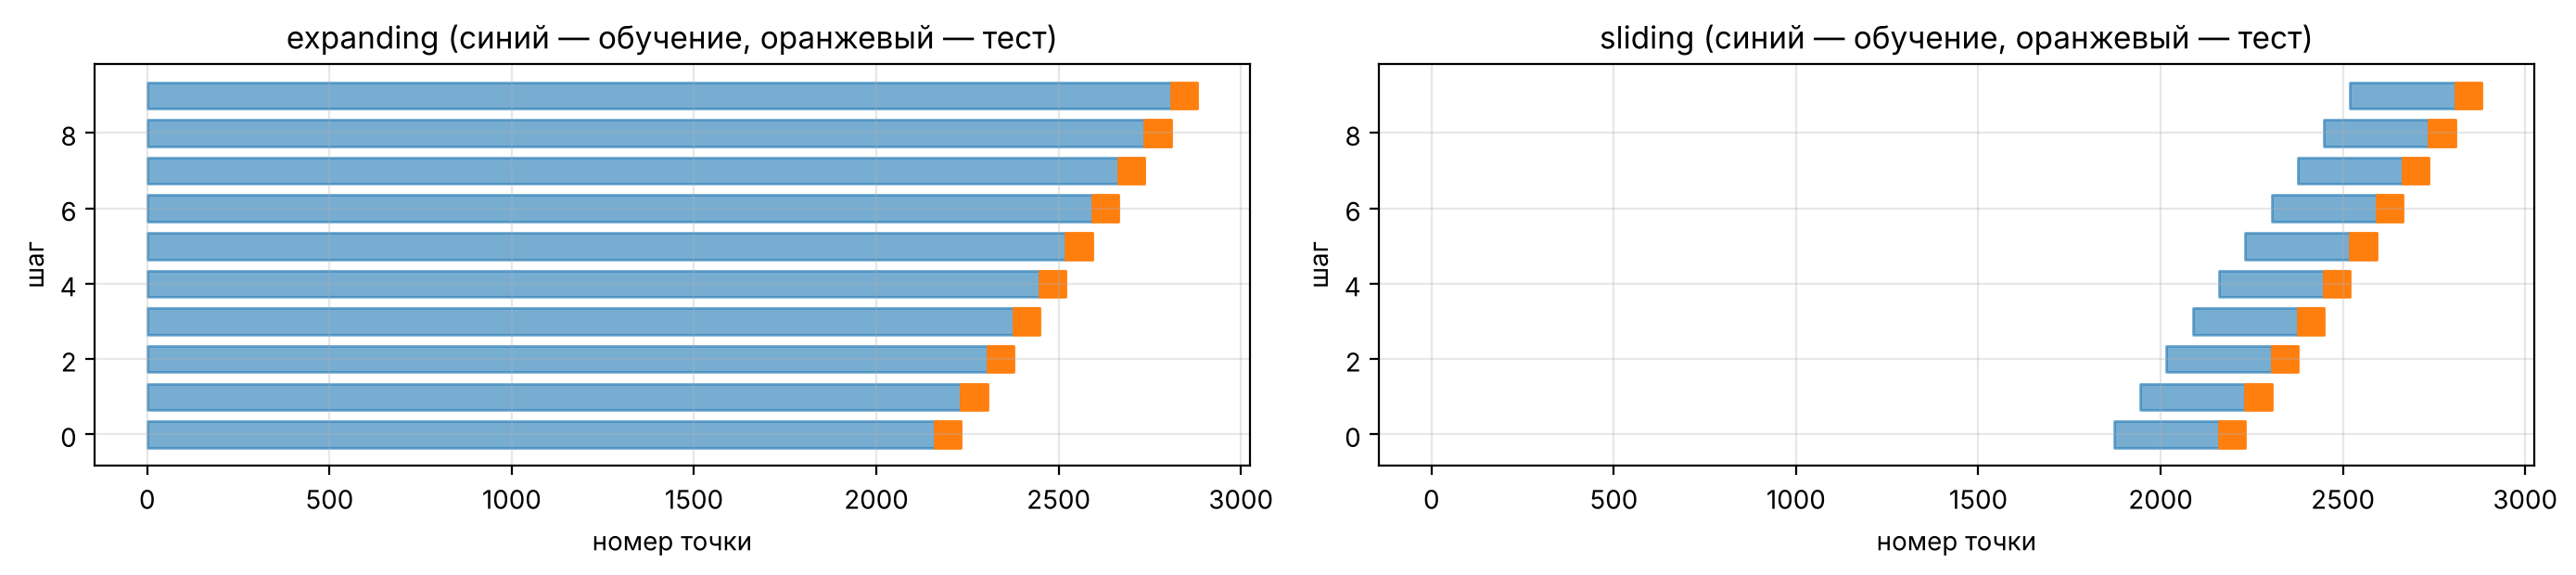

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.2), sharex=True)
for ax, scheme in zip(axes, ["expanding", "sliding"]):
    for k in range(N_STEPS):
        start = TEST_START + k * H
        tr0 = 0 if scheme == "expanding" else start - L
        ax.broken_barh([(tr0, start - tr0)], (k - 0.35, 0.7), color="C0", alpha=0.6)
        ax.broken_barh([(start, H)], (k - 0.35, 0.7), color="C1")
    ax.set_title(scheme + " (синий — обучение, оранжевый — тест)"); ax.set_xlabel("номер точки"); ax.set_ylabel("шаг")
plt.tight_layout(); plt.show()

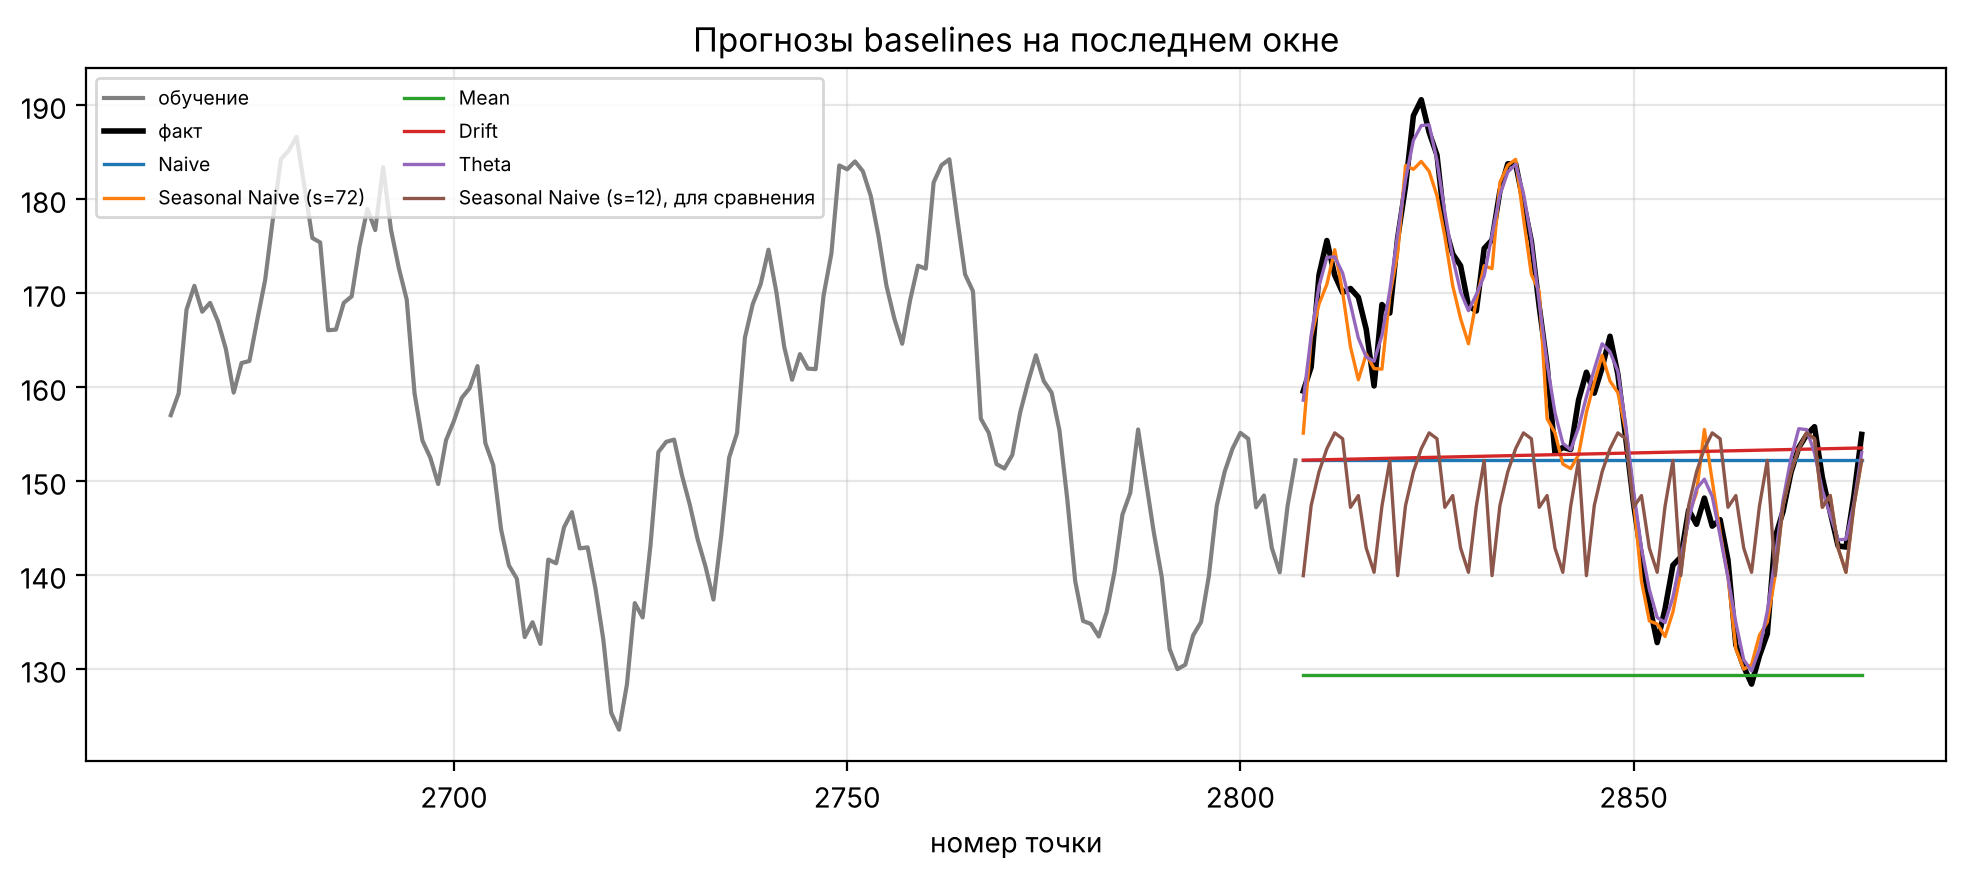

In [7]:
# Прогнозы всех baselines на последнем тестовом окне (схема expanding)
k = N_STEPS - 1
start = TEST_START + k * H
fig, ax = plt.subplots(figsize=(12, 4.5))
lo = start - 2 * S
ax.plot(range(lo, start), ya[lo:start], color="gray", label="обучение")
ax.plot(range(start, start + H), ya[start:start + H], color="k", lw=2, label="факт")
for name, folds in res["expanding"].items():
    ax.plot(range(start, start + H), folds[k]["y_pred"], lw=1.2, label=name)
ax.legend(fontsize=7, ncol=2); ax.set_title("Прогнозы baselines на последнем окне"); ax.set_xlabel("номер точки")
plt.show()

## 4. Метрики

MAE, RMSE, MAPE, sMAPE, MASE и Bias (среднее смещение). Ошибки по всем окнам собираются вместе. MASE считается по каждому окну как MAE модели, делённый на MAE сезонного naive на обучающей выборке этого окна (`s = 72`), затем усредняется по окнам: `MASE < 1` значит, что baseline точнее сезонного naive «в прошлом».

In [8]:
def metrics(folds):
    yt = np.concatenate([f["y_true"] for f in folds])
    yp = np.concatenate([f["y_pred"] for f in folds])
    e = yt - yp
    mase_folds = [np.mean(np.abs(f["y_true"] - f["y_pred"])) / f["scale"] for f in folds]
    return {
        "MAE": np.mean(np.abs(e)),
        "RMSE": np.sqrt(np.mean(e ** 2)),
        "MAPE, %": 100 * np.mean(np.abs(e / yt)),
        "sMAPE, %": 100 * np.mean(2 * np.abs(e) / (np.abs(yt) + np.abs(yp))),
        "MASE": np.mean(mase_folds),
        "Bias": np.mean(e),
    }


tables = {scheme: pd.DataFrame({name: metrics(f) for name, f in d.items()}).T for scheme, d in res.items()}

print("Схема expanding:")
display(tables["expanding"].round(2))
print("Схема sliding (окно 288):")
display(tables["sliding"].round(2))

Схема expanding:


,MAE,RMSE,"MAPE, %","sMAPE, %",MASE,Bias
Naive,14.20,17.08,9.10,9.37,5.63,6.62
Seasonal Naive (s=72),2.64,3.32,1.74,1.76,1.05,1.46
Mean,26.73,30.88,16.65,18.62,10.59,26.52
Drift,14.31,17.10,9.21,9.45,5.67,5.96
Theta,1.75,2.18,1.16,1.16,0.69,0.50
"Seasonal Naive (s=12), для сравнения",15.16,18.75,9.50,10.06,6.01,11.20


Схема sliding (окно 288):


,MAE,RMSE,"MAPE, %","sMAPE, %",MASE,Bias
Naive,14.20,17.08,9.10,9.37,5.39,6.62
Seasonal Naive (s=72),2.64,3.32,1.74,1.76,1.00,1.46
Mean,13.55,16.10,8.84,8.94,5.14,3.64
Drift,14.22,17.10,9.12,9.39,5.40,6.51
Theta,2.00,2.49,1.33,1.33,0.76,0.40
"Seasonal Naive (s=12), для сравнения",15.16,18.75,9.50,10.06,5.75,11.20


## 5. Сравнение и устойчивость оценки

In [9]:
comp = {}
for scheme, t in tables.items():
    comp[scheme] = {m: t[m].idxmin() for m in ["MAE", "RMSE", "sMAPE, %", "MASE"]}
display(pd.DataFrame(comp))

# устойчивость по окнам: разброс MASE между 10 окнами
stab = {}
for scheme, d in res.items():
    rows = {}
    for name, folds in d.items():
        m = np.array([np.mean(np.abs(f["y_true"] - f["y_pred"])) / f["scale"] for f in folds])
        rows[name] = {"mean": m.mean(), "std": m.std(ddof=1), "min": m.min(), "max": m.max()}
    stab[scheme] = pd.DataFrame(rows).T
print("MASE по 10 окнам, схема expanding:")
display(stab["expanding"].round(2))
print("MASE по 10 окнам, схема sliding:")
display(stab["sliding"].round(2))

,expanding,sliding
MAE,Theta,Theta
RMSE,Theta,Theta
"sMAPE, %",Theta,Theta
MASE,Theta,Theta


MASE по 10 окнам, схема expanding:


,mean,std,min,max
Naive,5.63,0.19,5.25,5.85
Seasonal Naive (s=72),1.05,0.09,0.84,1.17
Mean,10.59,0.76,9.58,11.70
Drift,5.67,0.18,5.31,5.87
Theta,0.69,0.06,0.60,0.81
"Seasonal Naive (s=12), для сравнения",6.01,0.11,5.79,6.16


MASE по 10 окнам, схема sliding:


,mean,std,min,max
Naive,5.39,0.32,4.84,5.94
Seasonal Naive (s=72),1.00,0.11,0.78,1.21
Mean,5.14,0.27,4.74,5.74
Drift,5.40,0.31,4.87,5.93
Theta,0.76,0.09,0.65,0.94
"Seasonal Naive (s=12), для сравнения",5.75,0.31,5.34,6.34


### MAPE осторожно

MAPE делит на фактическое значение. Сдвинем ряд вниз на его среднее значение на тестовом участке: значения станут около нуля и будут пересекать его. Ошибки, MAE, RMSE и MASE при этом **не изменятся**, а MAPE и sMAPE развалятся.

In [10]:
shift = float(np.round(ya[TEST_START:].mean()))   # уровень тестового участка
print("Сдвиг ряда на", shift)
rows = {}
for name, folds in res["expanding"].items():
    yt = np.concatenate([f["y_true"] for f in folds]); yp = np.concatenate([f["y_pred"] for f in folds])
    ys, ps = yt - shift, yp - shift
    rows[name] = {
        "MAE (оба ряда)": np.mean(np.abs(yt - yp)),
        "MAPE, %, исходный": 100 * np.mean(np.abs((yt - yp) / yt)),
        "MAPE, %, сдвинутый": 100 * np.mean(np.abs((ys - ps) / ys)),
        "sMAPE, %, исходный": 100 * np.mean(2 * np.abs(yt - yp) / (np.abs(yt) + np.abs(yp))),
        "sMAPE, %, сдвинутый": 100 * np.mean(2 * np.abs(ys - ps) / (np.abs(ys) + np.abs(ps))),
    }
print("Минимальное |значение| после сдвига: %.3f" % np.min(np.abs(np.concatenate([f["y_true"] for f in res["expanding"]["Naive"]]) - shift)))
pd.DataFrame(rows).T.round(2)

Сдвиг ряда на 152.0
Минимальное |значение| после сдвига: 0.187


,MAE (оба ряда),"MAPE, %, исходный","MAPE, %, сдвинутый","sMAPE, %, исходный","sMAPE, %, сдвинутый"
Naive,14.20,9.10,173.19,9.37,145.79
Seasonal Naive (s=72),2.64,1.74,53.73,1.76,36.91
Mean,26.73,16.65,542.31,18.62,140.65
Drift,14.31,9.21,169.13,9.45,146.27
Theta,1.75,1.16,35.77,1.16,27.75
"Seasonal Naive (s=12), для сравнения",15.16,9.50,255.88,10.06,129.24


## 6. Интервальный прогноз для Seasonal Naive

Наивный интервал строится по **эмпирическим квантилям ошибок backtesting**: для каждого горизонта `h` берутся квантили 2.5% и 97.5% ошибок и прибавляются к прогнозу.

Чтобы не подгонять интервал под те же данные, на которых он проверяется:
* квантили считаются на **калибровочной части** (окна с шагом 1 точка от начала ряда до `TEST_START`);
* покрытие (coverage) и ширина (width) проверяются на **тестовой части** (окна с шагом 1 точка начиная с `TEST_START`). Окна перекрываются и поэтому не независимы, зато оценка покрытия по каждому `h` устойчивее, чем по 10 окнам.

Калибровочных окон: 1945, тестовых окон: 649
Покрытие 95%-интервала: среднее по горизонтам 0.946, min 0.945, max 0.951
Ширина интервала: среднее 11.00, min 10.99, max 11.01


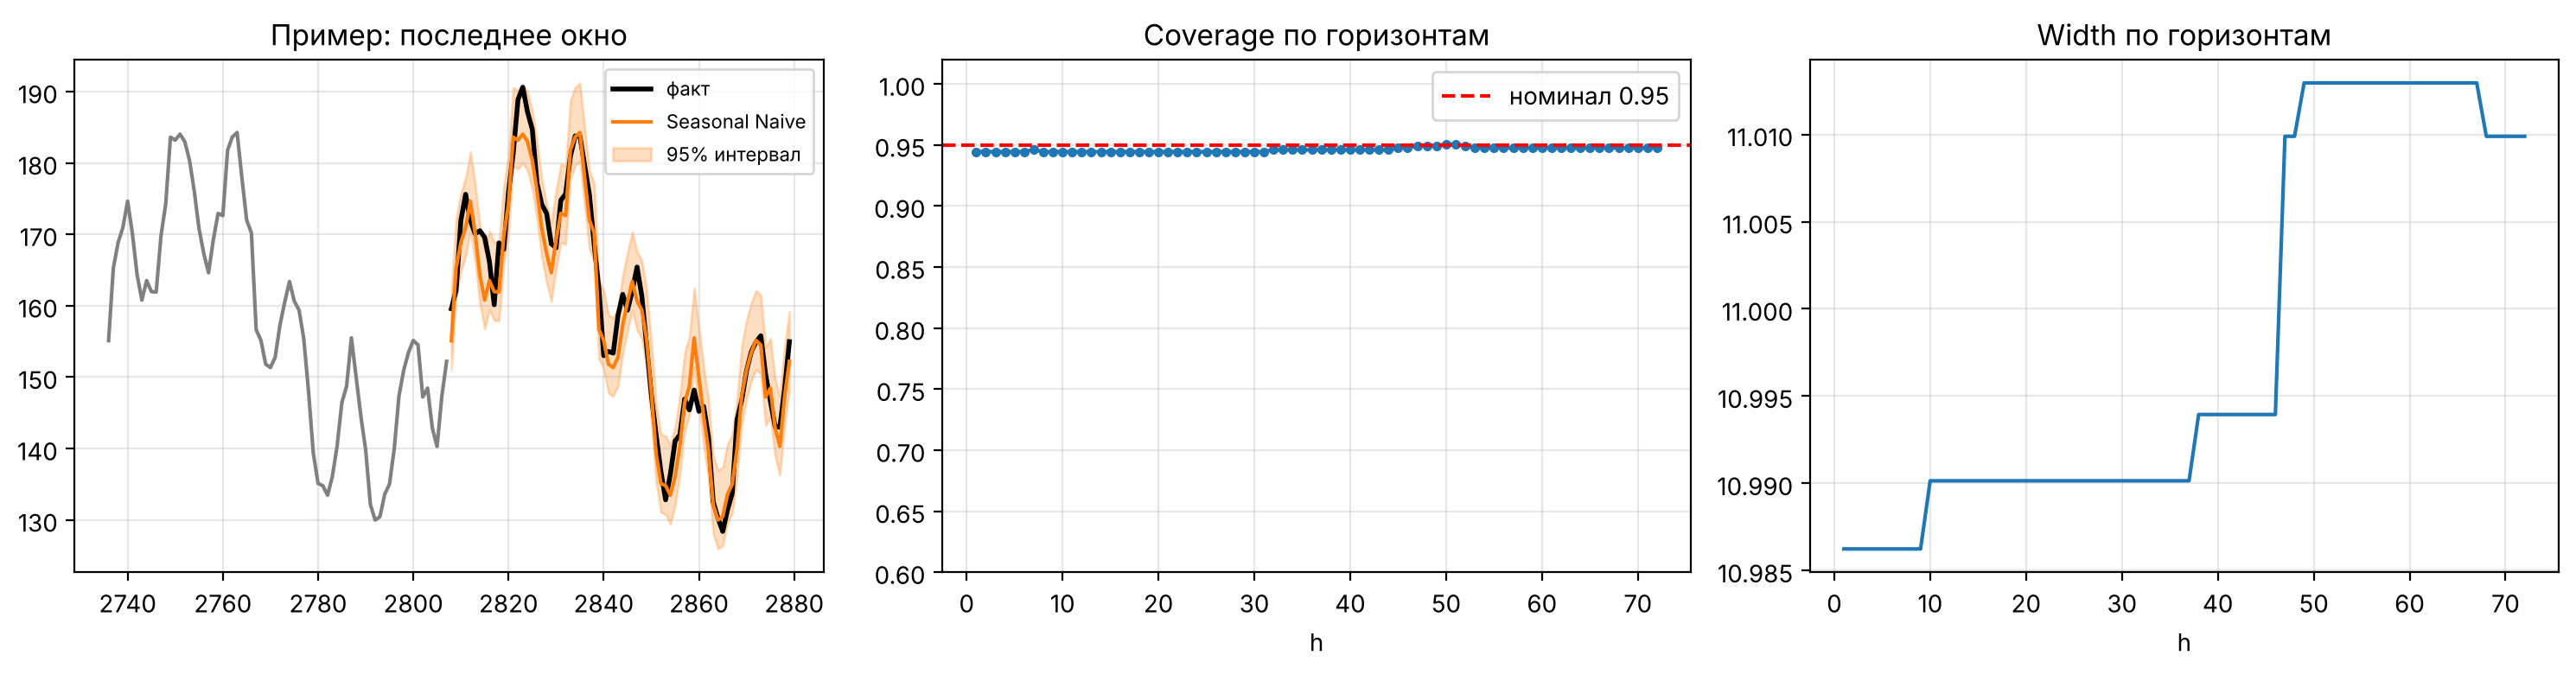

In [11]:
def sn_forecast(train, H):
    return seasonal_naive(train, H, s=S)

STEP = 1
cal_starts = list(range(S * 2, TEST_START - H + 1, STEP))
test_starts = list(range(TEST_START, N - H + 1, STEP))

E = np.array([ya[s_:s_ + H] - sn_forecast(ya[:s_], H) for s_ in cal_starts])    # ошибки калибровки: окна × горизонт
q_lo = np.quantile(E, 0.025, axis=0)
q_hi = np.quantile(E, 0.975, axis=0)

hit = np.zeros((len(test_starts), H), dtype=bool)
for i, s_ in enumerate(test_starts):
    fc = sn_forecast(ya[:s_], H)
    act = ya[s_:s_ + H]
    hit[i] = (act >= fc + q_lo) & (act <= fc + q_hi)

coverage_h = hit.mean(axis=0)
width_h = q_hi - q_lo
print("Калибровочных окон: %d, тестовых окон: %d" % (len(cal_starts), len(test_starts)))
print("Покрытие 95%%-интервала: среднее по горизонтам %.3f, min %.3f, max %.3f" % (coverage_h.mean(), coverage_h.min(), coverage_h.max()))
print("Ширина интервала: среднее %.2f, min %.2f, max %.2f" % (width_h.mean(), width_h.min(), width_h.max()))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
s_ = test_starts[-1]; fc = sn_forecast(ya[:s_], H)
lo = s_ - S
axes[0].plot(range(lo, s_), ya[lo:s_], color="gray")
axes[0].plot(range(s_, s_ + H), ya[s_:s_ + H], "k", lw=2, label="факт")
axes[0].plot(range(s_, s_ + H), fc, "C1", label="Seasonal Naive")
axes[0].fill_between(range(s_, s_ + H), fc + q_lo, fc + q_hi, color="C1", alpha=0.25, label="95% интервал")
axes[0].set_title("Пример: последнее окно"); axes[0].legend(fontsize=8)
axes[1].plot(range(1, H + 1), coverage_h, marker=".")
axes[1].axhline(0.95, color="r", ls="--", label="номинал 0.95"); axes[1].set_ylim(0.6, 1.02)
axes[1].set_title("Coverage по горизонтам"); axes[1].set_xlabel("h"); axes[1].legend()
axes[2].plot(range(1, H + 1), width_h)
axes[2].set_title("Width по горизонтам"); axes[2].set_xlabel("h")
plt.tight_layout(); plt.show()

## 7. Диагностика утечек: случайный split против корректных схем

У baselines обучения нет, поэтому утечку на них показать нельзя. Возьмём обучаемую модель — **RandomForest** на лаговых признаках — и прогнозируем на **H = 72 шага вперёд** (прямая стратегия): по значениям `y_t, y_{t−1}, y_{t−2}, y_{t−12}, y_{t−72}` и сезонным фазам предсказываем `y_{t+72}`.

Три схемы разбиения (около 25% строк в тесте):

1. **Случайный split** (неверно): строки перемешаны, соседние во времени строки попадают и в train, и в test.
2. **Блочный с очисткой (purge)**: тест — сплошной блок в середине ряда, из train удалены строки, чьи окна признаков/целей (±72 точки) пересекаются с тестом. Это убирает утечку через соседей, но это всё ещё не прогноз «в будущее».
3. **Хронологический** (верно): train — первые 75% времени, test — последующие, без пересечения по целям.

Для сравнения у каждой схемы считается Seasonal Naive на тех же тестовых строках (его прогноз `y_{t+72}` равен `y_t`). Отношение MAE модели к MAE Seasonal Naive показывает, обгоняет ли модель baseline.

In [12]:
def make_xy(y, H=H):
    n = len(y)
    t = np.arange(S, n - H)
    X = np.column_stack([
        y[t], y[t - 1], y[t - 2], y[t - 12], y[t - S],
        np.sin(2 * np.pi * t / 12), np.cos(2 * np.pi * t / 12),
        np.sin(2 * np.pi * t / S), np.cos(2 * np.pi * t / S),
    ])
    return t, X, y[t + H]


t_all, X_all, y_all = make_xy(ya)
n_rows = len(t_all)
scale_leak = mase_scale(ya[:int(0.75 * N)])      # одинаковый знаменатель MASE для всех схем

rng = np.random.default_rng(0)
perm = rng.permutation(n_rows)
n_test = int(0.25 * n_rows)

splits = {}
# 1. случайный
splits["случайный split (неверно)"] = (np.sort(perm[n_test:]), np.sort(perm[:n_test]))
# 2. блочный с purge
b0 = int(0.375 * n_rows); b1 = b0 + n_test
test_b = np.arange(b0, b1)
purge = (t_all >= t_all[b0] - 2 * S) & (t_all <= t_all[b1 - 1] + 2 * S)
splits["блочный с purge"] = (np.flatnonzero(~purge), test_b)
# 3. хронологический
split_t = int(0.75 * N)
splits["хронологический (верно)"] = (np.flatnonzero(t_all + H <= split_t), np.flatnonzero(t_all >= split_t))

rows = {}
for name, (tr, te) in splits.items():
    rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=0, n_jobs=-1)
    rf.fit(X_all[tr], y_all[tr])
    pred = rf.predict(X_all[te])
    err = y_all[te] - pred
    sn_err = y_all[te] - X_all[te][:, 0]          # Seasonal Naive: y_{t+72} = y_t
    rows[name] = {
        "строк train": len(tr), "строк test": len(te),
        "RF MAE": np.mean(np.abs(err)), "RF RMSE": np.sqrt(np.mean(err ** 2)),
        "RF MASE": np.mean(np.abs(err)) / scale_leak,
        "SN MAE": np.mean(np.abs(sn_err)),
        "RF MAE / SN MAE": np.mean(np.abs(err)) / np.mean(np.abs(sn_err)),
    }
leak = pd.DataFrame(rows).T
leak.round(2)

,строк train,строк test,RF MAE,RF RMSE,RF MASE,SN MAE,RF MAE / SN MAE
случайный split (неверно),2052.0,684.0,2.02,2.55,0.80,2.51,0.81
блочный с purge,1764.0,684.0,1.91,2.41,0.76,2.51,0.76
хронологический (верно),2017.0,648.0,2.48,3.34,0.99,2.64,0.94


## 8. Выводы

**Лучший baseline.** **Theta**: он первый по всем четырём метрикам (MAE, RMSE, sMAPE, MASE) в обеих схемах.

| Схема | Theta MAE / MASE | Seasonal Naive (s=72) MAE / MASE | Naive MAE / MASE |
|---|---|---|---|
| expanding | 1.75 / 0.69 | 2.64 / 1.05 | 14.20 / 5.63 |
| sliding (окно 288) | 2.00 / 0.76 | 2.64 / 1.00 | 14.20 / 5.39 |

* Seasonal Naive с правильным периодом 72 — планка «не хуже сезонного naive» (MASE ≈ 1 по определению); любая более сложная модель должна бить хотя бы его. Он с большим отрывом лучше Naive, Mean и Drift, потому что в ряду главное — сезонность, а не уровень.
* Seasonal Naive с неверным периодом 12 почти не лучше Naive (MASE 6.0): ошибка в периоде обесценивает метод.
* MAE у Theta (1.75) близок к нижней границе, которую задаёт шум: при σ = 2 даже идеальный прогноз ошибается в среднем на ≈ 1.6. Ряд почти детерминирован, как предупреждает лекция.
* Положительный Bias (у Naive 6.6, у Seasonal Naive 1.5, у Theta 0.5) показывает, что при росте все baselines систематически занижают прогноз. MAE этого не показывает, поэтому Bias стоит смотреть рядом.

**Метрики.** MAE, RMSE, sMAPE и MASE дают **одинаковое ранжирование** всех шести моделей в обеих схемах. Расходится только MAPE на «неудобном» ряду: после сдвига ряда на 152 вниз (значения около нуля, минимум |значение| 0.19) ошибки и MASE не меняются, а MAPE Seasonal Naive растёт с 1.7% до 54%, Mean — с 17% до 542%, sMAPE Seasonal Naive — с 1.8% до 37%; порядок Naive и Drift меняется местами. MASE оказывается самой устойчивой и сравнимой метрикой.

**Схемы валидации.**

* **Expanding** даёт более стабильную оценку: разброс MASE по 10 окнам (std) у Theta 0.06 против 0.09 у sliding, у Naive 0.19 против 0.32. Процесс стационарен в смысле структуры (константный тренд и сезонность), поэтому лишняя история только помогает.
* **Sliding** лучше для Mean (MAE 13.6 против 26.7: среднее по короткому окну отслеживает рост), но Mean всё равно далеко от лидеров. Выбор схемы меняет ранжирование слабых моделей (Mean — последний при expanding и третий при sliding), на лидеров не влияет. Seasonal Naive от схемы не зависит, так как использует только последний период.
* Схемы нужно сравнивать на одинаковых окнах (так и сделано).

**Интервалы Seasonal Naive (95%).** Квантили ошибок взяты на калибровочной части (1945 окон), покрытие проверено на отдельной тестовой (649 окон): покрытие 0.946 (по горизонтам от 0.945 до 0.951) при номинале 0.95, ширина 11.0. Интервал калиброван и не ухудшается с горизонтом, потому что ошибка Seasonal Naive на любом горизонте — это разность двух точек на расстоянии периода, то есть от `h` не зависит. У модельных интервалов (ARIMA, ETS) покрытие, как правило, падает с ростом `h`. Окна перекрываются, поэтому оценка точная, но не независимая.

**Утечка при случайном split** (RandomForest, прогноз на 72 шага):

| Схема | RF MAE | RF RMSE | RF MASE | RF MAE / SN MAE |
|---|---|---|---|---|
| случайный split (неверно) | 2.02 | 2.55 | 0.80 | 0.81 |
| блочный с purge | 1.91 | 2.41 | 0.76 | 0.76 |
| хронологический (верно) | 2.48 | 3.34 | 0.99 | 0.94 |

Случайный split завышает качество: MAE на 19% лучше, RMSE на 24% лучше, MASE 0.80 против 0.99. Верный вывод по хронологической схеме: RF едва лучше Seasonal Naive (0.94), а случайный split создаёт впечатление явного преимущества (0.81).

**Ограничения.**

* Ряд синтетический, результаты получены на одной реализации (один `seed`) и 10 окнах.
* Theta использован с аддитивной сезонной корректировкой и периодом 72; другие настройки могут изменить результат.
* Знаменатель MASE считается по сезонному naive (`s = 72`); при обычном naive значения будут другими.
* Утечку удалось показать только на обучаемой модели; у baselines обучения нет, и утечка на них невозможна.
